In [78]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              GradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier



In [80]:
df = pd.read_excel("Dry_Bean_Dataset.xlsx")

In [81]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [83]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [84]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [85]:
df.duplicated().sum()

np.int64(68)

In [86]:
df = df.drop_duplicates()

In [87]:
df.duplicated().sum()

np.int64(0)

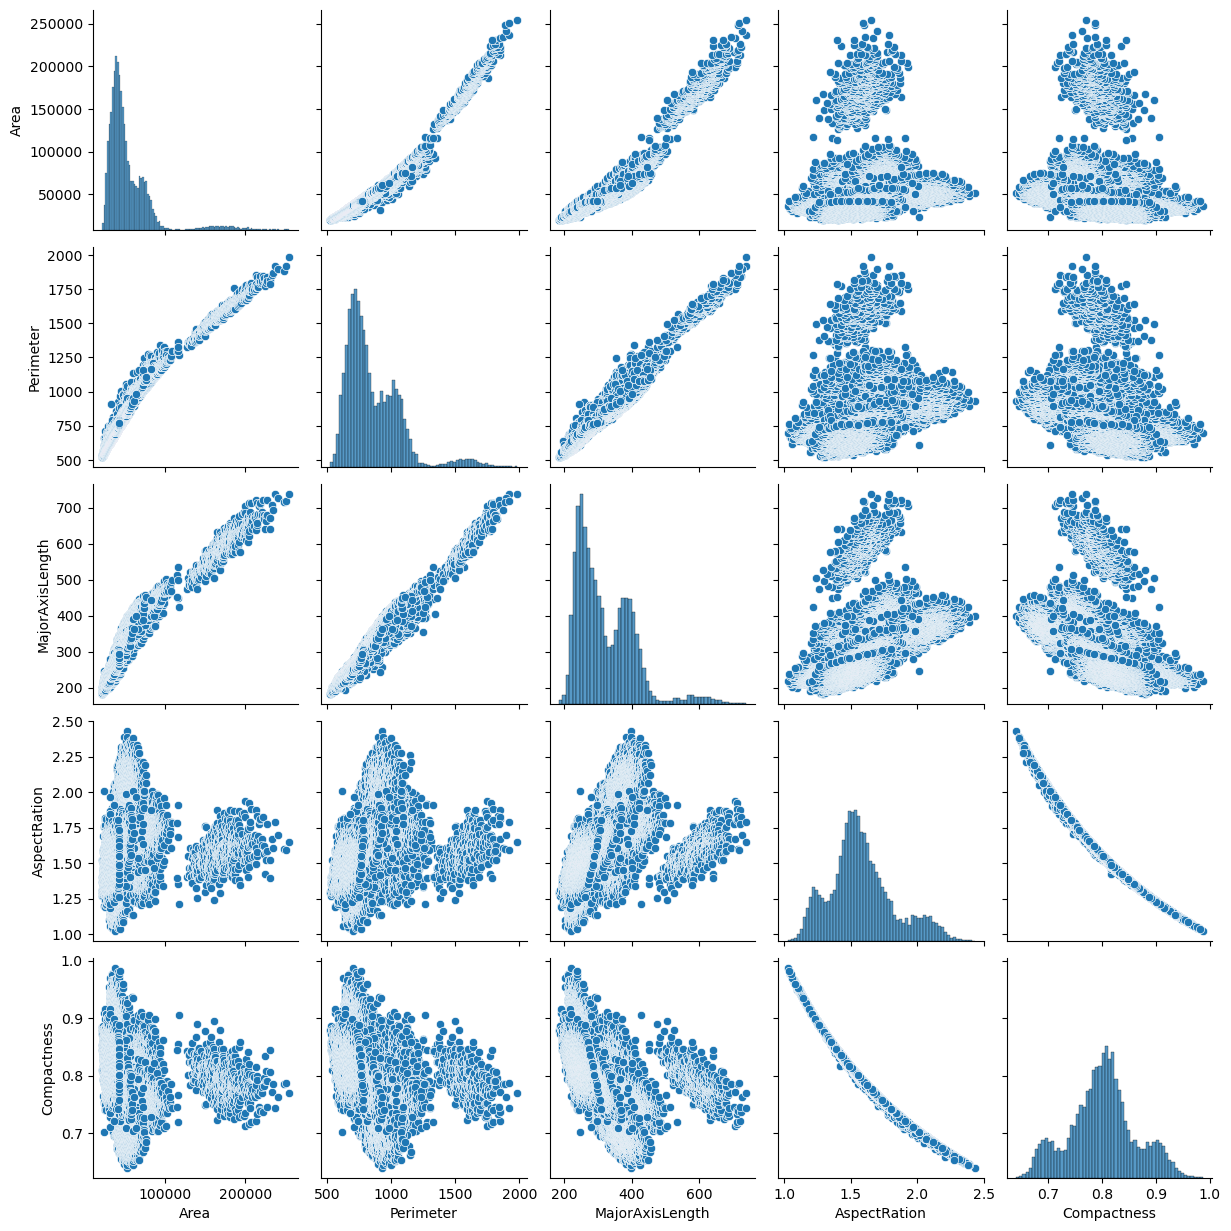

In [88]:
sns.pairplot(data = df[["Area", "Perimeter", "MajorAxisLength", "AspectRation", "Compactness"]])

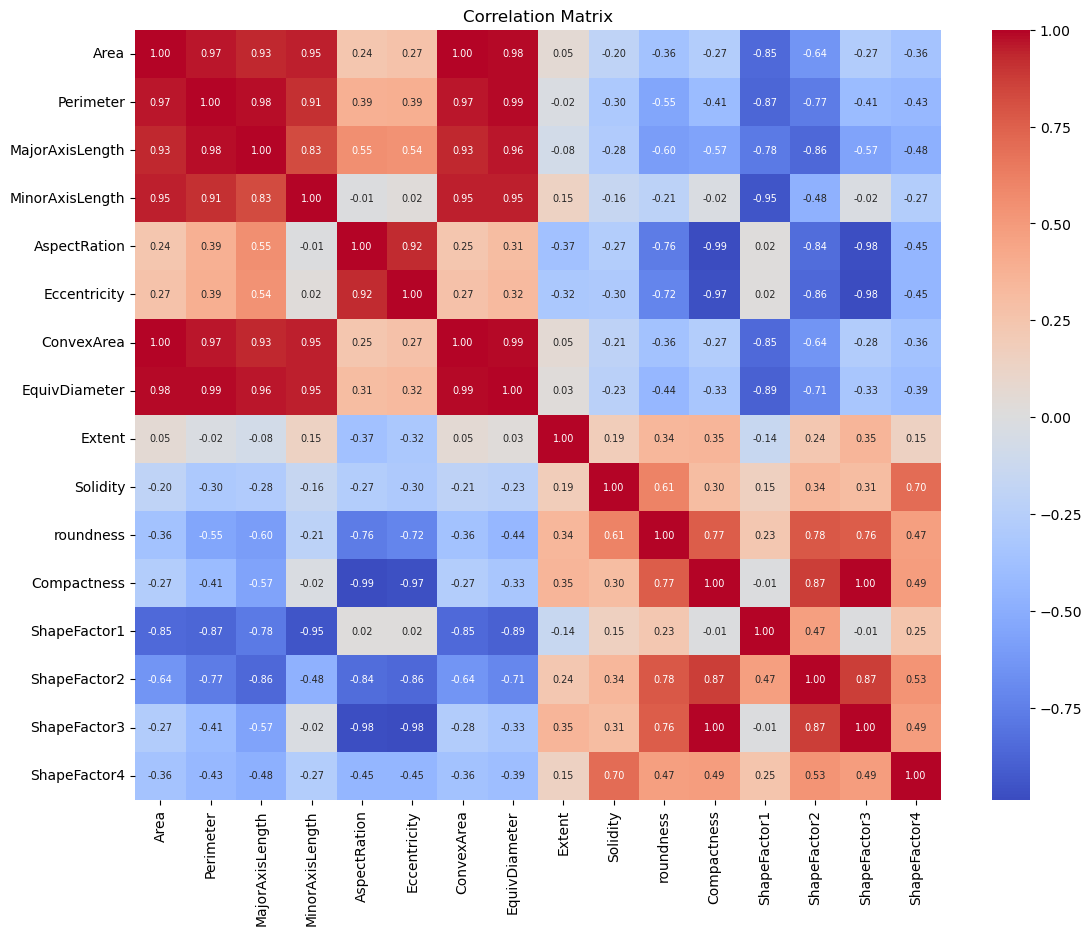

In [89]:
features_only = df.drop(columns="Class")
plt.figure(figsize=(13, 10))
sns.heatmap(features_only.corr(), annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation Matrix")
plt.show()

In [90]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df["Class"])   
X = df.drop(columns="Class")        
classes = le.classes_              
print(classes)

['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


In [91]:
x = df.drop(columns = 'Class')
y = df.Class

In [92]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape, x_test.shape)
print(y_train.shape, y_test.shape)

(10834, 16) (2709, 16)
(10834,) (2709,)


In [93]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)

train_acc = dt.score(x_train, y_train)
test_acc = dt.score(x_test, y_test)
print(f"Training accuracy: {train_acc:.4f}")
print(f"Test accuracy    : {test_acc:.4f}")
print(f"Tree depth: {dt.get_depth()} | Leaves: {dt.get_n_leaves()}")

Training accuracy: 1.0000
Test accuracy    : 0.8966
Tree depth: 27 | Leaves: 694




In [94]:
plt.figure(figsize=(26, 11),dpi=500)
plot_tree(dt, max_depth=4, filled=True,
          feature_names=X.columns,   
          class_names=classes,      
          fontsize=7)
plt.show()

In [95]:
t = dt.tree_

def describe(node):
    f = X.columns[t.feature[node]]
    thr = t.threshold[node]
    print(f"Node {node}: {f} <= {thr:.2f}   (samples={t.n_node_samples[node]})")
    for side, child in [("YES (<=)", t.children_left[node]), ("NO  (>) ", t.children_right[node])]:
        v = t.value[child][0]
        v = v / v.sum()
        top = [f"{classes[i]} {v[i]*100:.0f}%" for i in np.argsort(-v) if v[i] > 0.10]
        print(f"   {side}: {', '.join(top)}")

root = 0
for node in [root, t.children_left[root], t.children_right[root]]:
    describe(node)
    print()

Node 0: MajorAxisLength <= 280.70   (samples=10834)
   YES (<=): DERMASON 59%, SEKER 33%
   NO  (>) : SIRA 28%, HOROZ 24%, CALI 21%, BARBUNYA 17%

Node 1: ShapeFactor1 <= 0.01   (samples=4597)
   YES (<=): SEKER 87%
   NO  (>) : DERMASON 88%

Node 608: ShapeFactor3 <= 0.53   (samples=6237)
   YES (<=): HOROZ 93%
   NO  (>) : SIRA 36%, CALI 25%, BARBUNYA 22%



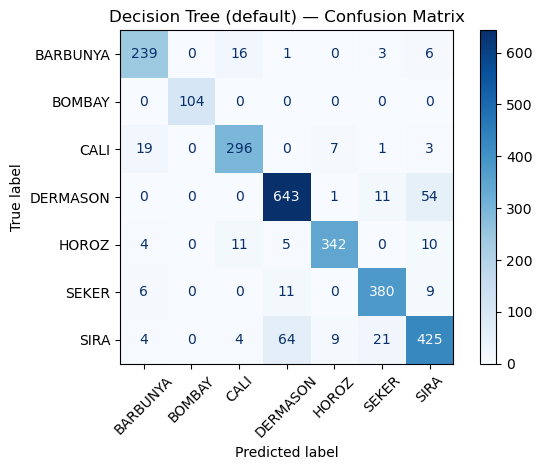

Error rate per class:
SIRA        0.194
BARBUNYA    0.098
DERMASON    0.093
CALI        0.092
HOROZ       0.081
SEKER       0.064
BOMBAY      0.000
dtype: float64

Most confused pairs (true -> predicted):
  SIRA -> DERMASON: 64 samples
  DERMASON -> SIRA: 54 samples
  SIRA -> SEKER: 21 samples
  CALI -> BARBUNYA: 19 samples


In [96]:
from sklearn.metrics import ConfusionMatrixDisplay
pred = dt.predict(x_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=classes,
                                        xticks_rotation=45, cmap="Blues")
plt.title("Decision Tree (default) — Confusion Matrix")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, pred)
err = pd.Series(1 - np.diag(cm) / cm.sum(axis=1), index=classes).sort_values(ascending=False)
print("Error rate per class:")
print(err.round(3))

off = cm.copy()
np.fill_diagonal(off, 0)
print("\nMost confused pairs (true -> predicted):")
for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:4], off.shape)):
    print(f"  {classes[i]} -> {classes[j]}: {off[i, j]} samples")

In [97]:
rows = []

def run(label, model):
    model.fit(x_train, y_train)
    rows.append([label, model.score(x_train, y_train), model.score(x_test, y_test), model.get_depth()])
run("Default", DecisionTreeClassifier(random_state=42))
for crit in ["gini", "entropy"]:
    run(f"criterion={crit}", DecisionTreeClassifier(criterion=crit, random_state=42))
for d in [2, 4, 6, 10, 15]:
    run(f"max_depth={d}", DecisionTreeClassifier(max_depth=d, random_state=42))

Best ccp_alpha = 0.000168  (test acc = 0.9121)


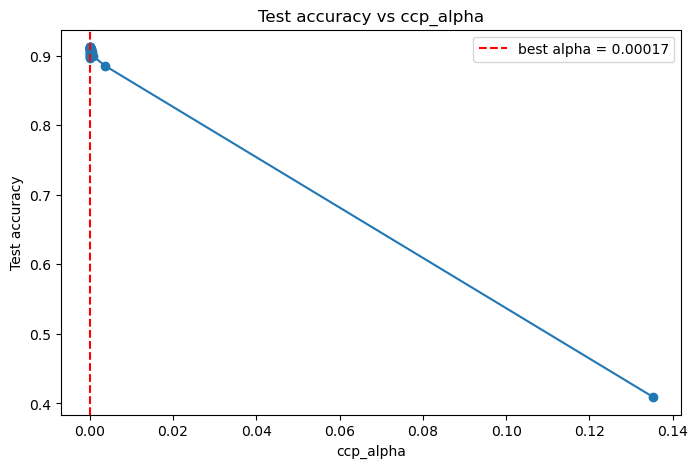

In [98]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(x_train, y_train)
alphas = path.ccp_alphas[:-1]                                    
alphas = alphas[np.linspace(0, len(alphas) - 1, 30).astype(int)] 
alphas = np.unique(alphas)

test_accs = []
for a in alphas:
    m = DecisionTreeClassifier(ccp_alpha=a, random_state=42).fit(x_train, y_train)
    test_accs.append(m.score(x_test, y_test))

best_alpha = alphas[int(np.argmax(test_accs))]
print(f"Best ccp_alpha = {best_alpha:.6f}  (test acc = {max(test_accs):.4f})")

plt.figure(figsize=(8, 5))
plt.plot(alphas, test_accs, marker="o")
plt.axvline(best_alpha, color="red", ls="--", label=f"best alpha = {best_alpha:.5f}")
plt.xlabel("ccp_alpha")
plt.ylabel("Test accuracy")
plt.title("Test accuracy vs ccp_alpha")
plt.legend()
plt.show()

run(f"ccp_alpha={best_alpha:.5f} (best)", DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42))

In [99]:
table = pd.DataFrame(rows, columns=["Variant", "Train Acc", "Test Acc", "Depth"])
table["Gap (Train-Test)"] = table["Train Acc"] - table["Test Acc"]
table.round(4)

,Variant,Train Acc,Test Acc,Depth,Gap (Train-Test)
0,Default,1.0000,0.8966,27,0.1034
1,criterion=gini,1.0000,0.8966,27,0.1034
2,criterion=entropy,1.0000,0.8885,18,0.1115
3,max_depth=2,0.6553,0.6519,2,0.0034
4,max_depth=4,0.8279,0.8158,4,0.0121
5,max_depth=6,0.9145,0.8830,6,0.0315
6,max_depth=10,0.9655,0.9037,10,0.0618
7,max_depth=15,0.9934,0.9014,15,0.0920
8,ccp_alpha=0.00017 (best),0.9729,0.9121,16,0.0607


In [100]:
def show_cm(model, title):
    pred = model.predict(x_test)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=classes,
                                            xticks_rotation=45, cmap="Blues")
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [101]:
single_svm = make_pipeline(StandardScaler(), SVC())     
single_dt = DecisionTreeClassifier(random_state=42)
single_svm.fit(x_train, y_train)
single_dt.fit(x_train, y_train)

# Bagging: SVM
svm_bag = BaggingClassifier(
    estimator=make_pipeline(StandardScaler(), SVC()),
    n_estimators=10, max_samples=0.5,
    random_state=42, n_jobs=-1)
svm_bag.fit(x_train, y_train)

dt_bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50, random_state=42, n_jobs=-1)
dt_bag.fit(x_train, y_train)

acc = {
    "SVM single": single_svm.score(x_test, y_test),
    "SVM bagged": svm_bag.score(x_test, y_test),
    "DT single": single_dt.score(x_test, y_test),
    "DT bagged": dt_bag.score(x_test, y_test),
}
for k, v in acc.items():
    print(f"{k:12s} test accuracy = {v:.4f}")

SVM single   test accuracy = 0.9210
SVM bagged   test accuracy = 0.9210
DT single    test accuracy = 0.8966
DT bagged    test accuracy = 0.9151


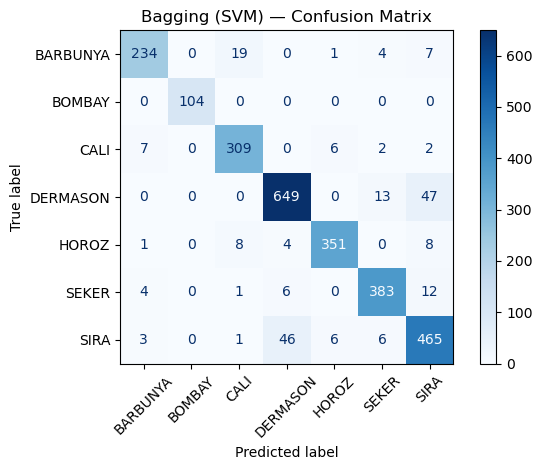

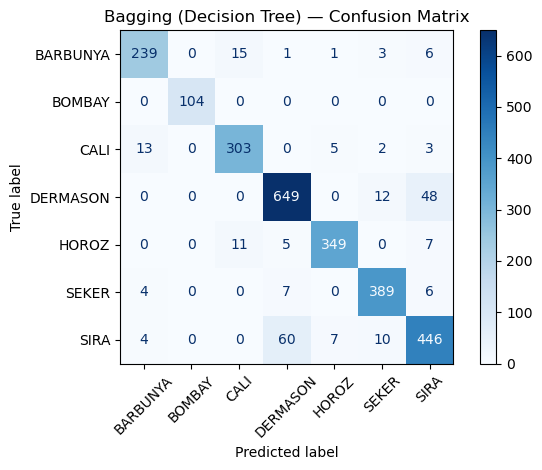

In [102]:
show_cm(svm_bag, "Bagging (SVM) — Confusion Matrix")
show_cm(dt_bag, "Bagging (Decision Tree) — Confusion Matrix")

In [103]:
cmp = pd.DataFrame({
    "Single": [acc["SVM single"], acc["DT single"]],
    "Bagged": [acc["SVM bagged"], acc["DT bagged"]],
}, index=["SVM", "Decision Tree"])
cmp["Improvement"] = cmp["Bagged"] - cmp["Single"]
cmp.round(4)

,Single,Bagged,Improvement
SVM,0.9210,0.9210,0.0000
Decision Tree,0.8966,0.9151,0.0185


Random Forest baseline accuracy = 0.9199


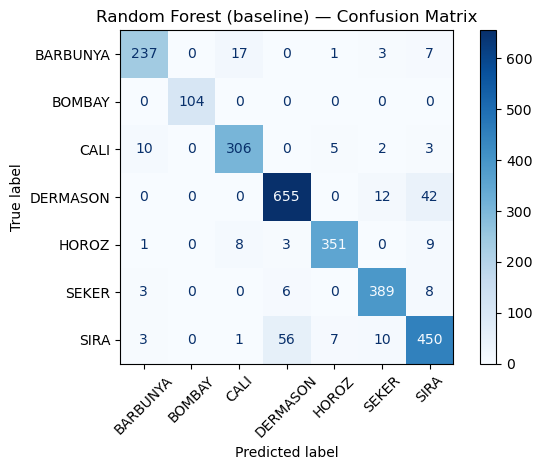

In [104]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)
print(f"Random Forest baseline accuracy = {rf.score(x_test, y_test):.4f}")
show_cm(rf, "Random Forest (baseline) — Confusion Matrix")

n_estimators= 10  accuracy=0.9144
n_estimators= 50  accuracy=0.9177
n_estimators=100  accuracy=0.9199
n_estimators=150  accuracy=0.9188
n_estimators=200  accuracy=0.9195


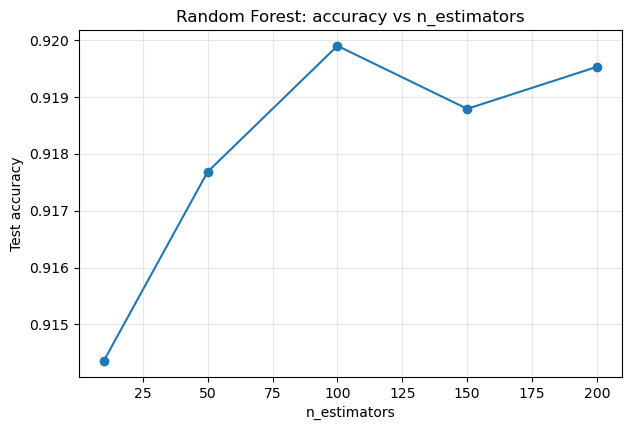

Best n_estimators: 100


In [105]:
n_list = [10, 50, 100, 150, 200]
rf_accs = []
for n in n_list:
    m = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1).fit(x_train, y_train)
    rf_accs.append(m.score(x_test, y_test))
    print(f"n_estimators={n:3d}  accuracy={rf_accs[-1]:.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(n_list, rf_accs, marker="o")
plt.xlabel("n_estimators")
plt.ylabel("Test accuracy")
plt.title("Random Forest: accuracy vs n_estimators")
plt.grid(alpha=0.3)
plt.show()

best_n = n_list[int(np.argmax(rf_accs))]
print("Best n_estimators:", best_n)

In [106]:
mf_accs = {}
for mf in ["sqrt", "log2", 8]:
    m = RandomForestClassifier(n_estimators=best_n, max_features=mf,
                               random_state=42, n_jobs=-1).fit(x_train, y_train)
    mf_accs[mf] = m.score(x_test, y_test)
    print(f"max_features={str(mf):5s} accuracy={mf_accs[mf]:.4f}")

best_mf = max(mf_accs, key=mf_accs.get)
print("Best max_features:", best_mf)

max_features=sqrt  accuracy=0.9199
max_features=log2  accuracy=0.9199
max_features=8     accuracy=0.9184
Best max_features: sqrt


Best RF accuracy = 0.9199


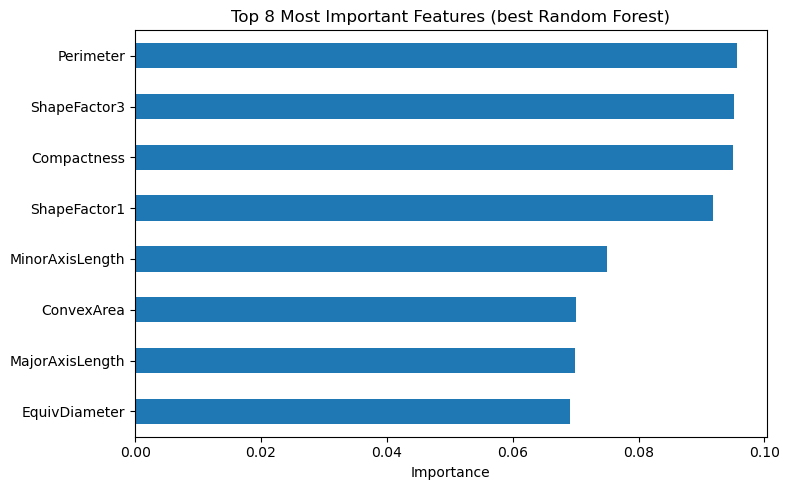

Perimeter          0.0956
ShapeFactor3       0.0951
Compactness        0.0950
ShapeFactor1       0.0918
MinorAxisLength    0.0750
ConvexArea         0.0701
MajorAxisLength    0.0700
EquivDiameter      0.0691
dtype: float64


In [107]:
best_rf = RandomForestClassifier(n_estimators=best_n, max_features=best_mf,
                                 random_state=42, n_jobs=-1).fit(x_train, y_train)
print(f"Best RF accuracy = {best_rf.score(x_test, y_test):.4f}")

imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top8 = imp.head(8)

plt.figure(figsize=(8, 5))
top8.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Top 8 Most Important Features (best Random Forest)")
plt.tight_layout()
plt.show()
print(top8.round(4))

n_estimators: {10: 0.9066076042820229, 50: 0.9165743816906607, 100: 0.9176818014027316, 200: 0.9150978220745662}


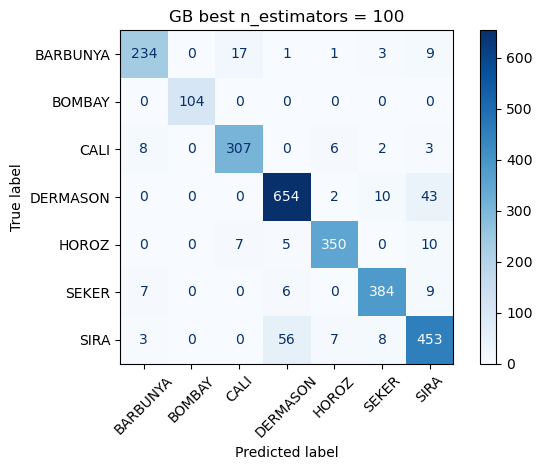

In [108]:
gb_n = {}
for n in [10, 50, 100, 200]:
    m = GradientBoostingClassifier(n_estimators=n, random_state=42).fit(x_train, y_train)
    gb_n[n] = m.score(x_test, y_test)
    if n == max(gb_n, key=gb_n.get):
        best_n_model = m
print("n_estimators:", gb_n)
best_n = max(gb_n, key=gb_n.get)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_n_model.predict(x_test), display_labels=classes,
    xticks_rotation=45, cmap="Blues")
plt.title(f"GB best n_estimators = {best_n}")
plt.tight_layout()
plt.show()

learning_rate: {0.1: 0.9176818014027316, 0.3: 0.9117755629383536, 0.5: 0.9114064230343301, 0.9: 0.9062384643779993}


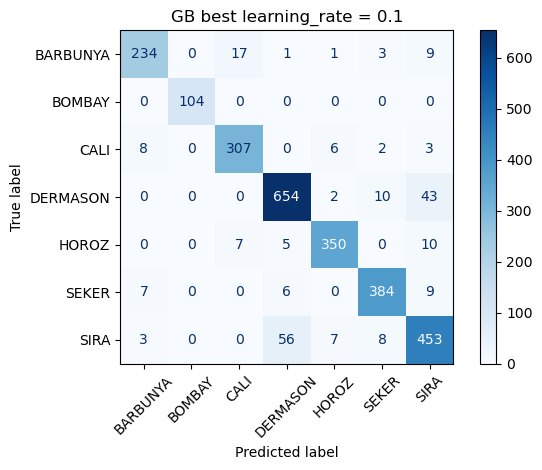

In [109]:
gb_lr = {}
best_lr_model = None
for lr in [0.1, 0.3, 0.5, 0.9]:
    m = GradientBoostingClassifier(n_estimators=best_n, learning_rate=lr,
                                   random_state=42).fit(x_train, y_train)
    gb_lr[lr] = m.score(x_test, y_test)
    if gb_lr[lr] == max(gb_lr.values()):
        best_lr_model = m
print("learning_rate:", gb_lr)
best_lr = max(gb_lr, key=gb_lr.get)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_lr_model.predict(x_test), display_labels=classes,
    xticks_rotation=45, cmap="Blues")
plt.title(f"GB best learning_rate = {best_lr}")
plt.tight_layout()
plt.show()

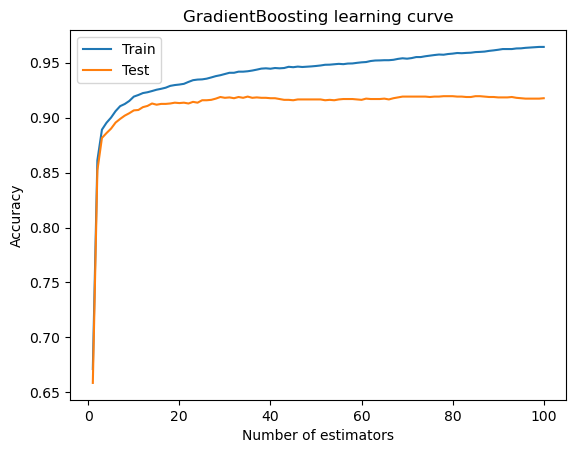

In [111]:
gb = GradientBoostingClassifier(
    n_estimators=best_n,
    learning_rate=best_lr,
    random_state=42
)
gb.fit(x_train, y_train)
train_curve = [
    accuracy_score(y_train, p)
    for p in gb.staged_predict(x_train)
]
test_curve = [
    accuracy_score(y_test, p)
    for p in gb.staged_predict(x_test)
]
plt.plot(range(1, best_n + 1), train_curve, label="Train")
plt.plot(range(1, best_n + 1), test_curve, label="Test")
plt.xlabel("Number of estimators")
plt.ylabel("Accuracy")
plt.legend()
plt.title("GradientBoosting learning curve")
plt.show()

In [ ]:
def make_xgb(subsample=1.0):
    return XGBClassifier(n_estimators=best_n, learning_rate=best_lr,
                         subsample=subsample, random_state=42,
                         eval_metric="mlogloss", n_jobs=-1)

xgb = make_xgb(1.0)
results["XGBoost"] = evaluate("XGBoost", xgb, show_cm=True)
models["XGBoost"] = xgb

for s in [0.6, 0.8, 1.0]:
    r = evaluate(f"subsample={s}", make_xgb(s))
    print(f"subsample={s}: test acc = {r['Accuracy']:.4f}")
    

NameError: name 'evaluate' is not defined

In [116]:
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate(name, model, show_cm=False):
    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)

    acc = accuracy_score(y_test, y_pred)

    if show_cm:
        cm = confusion_matrix(y_test, y_pred)

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title(f"{name} - Confusion Matrix")
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.show()

    return {
        "Accuracy": acc
    }


In [118]:
from sklearn.preprocessing import LabelEncoder

y = df['Class']

le = LabelEncoder()
y = le.fit_transform(y)

In [120]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [121]:
print(y_train[:10])
print(y_test[:10])
print(le.classes_)

[2 0 4 6 2 3 2 5 3 2]
[5 3 3 4 5 3 3 3 0 3]
['BARBUNYA' 'BOMBAY' 'CALI' 'DERMASON' 'HOROZ' 'SEKER' 'SIRA']


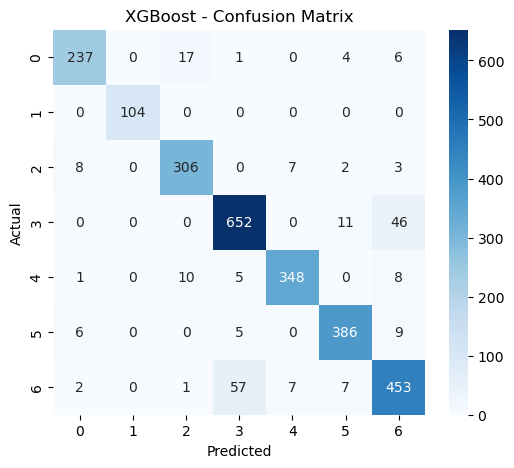

subsample=0.6: test acc = 0.9206
subsample=0.8: test acc = 0.9206
subsample=1.0: test acc = 0.9177


In [124]:
results = {}   
models = {}    
def make_xgb(subsample=1.0):

    return XGBClassifier(
        n_estimators=best_n,
        learning_rate=best_lr,
        subsample=subsample,
        random_state=42,
        eval_metric="mlogloss",
        n_jobs=-1
    )

xgb = make_xgb(1.0)

results["XGBoost"] = evaluate("XGBoost", xgb, show_cm=True)

models["XGBoost"] = xgb

for s in [0.6, 0.8, 1.0]:

    r = evaluate(f"subsample={s}", make_xgb(s))

    print(f"subsample={s}: test acc = {r['Accuracy']:.4f}")

In [126]:
print(results.keys())

dict_keys(['XGBoost'])


In [127]:
cmp = pd.DataFrame(results).T.loc[
    ["Bagging DT", "RandomForest", "Gradient Boosting", "XGBoost"],
    ["Accuracy", "Time(s)"]
]

print(cmp.round(4))

KeyError: "['Bagging DT', 'RandomForest', 'Gradient Boosting'] not in index"

In [135]:
summary = pd.DataFrame(results).T[
    ["Precision", "Recall", "Accuracy", "F1"]
]

print(summary.round(4))

KeyError: "['Precision', 'Recall', 'F1'] not in index"

In [129]:
best_name = summary["Accuracy"].idxmax()
print("Best model:", best_name)

NameError: name 'summary' is not defined

Components needed for 95% variance: 4


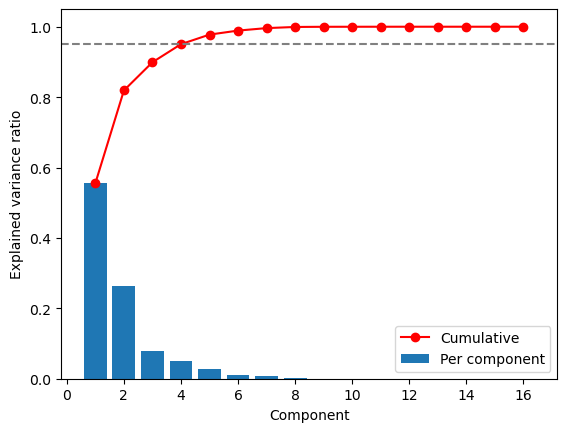

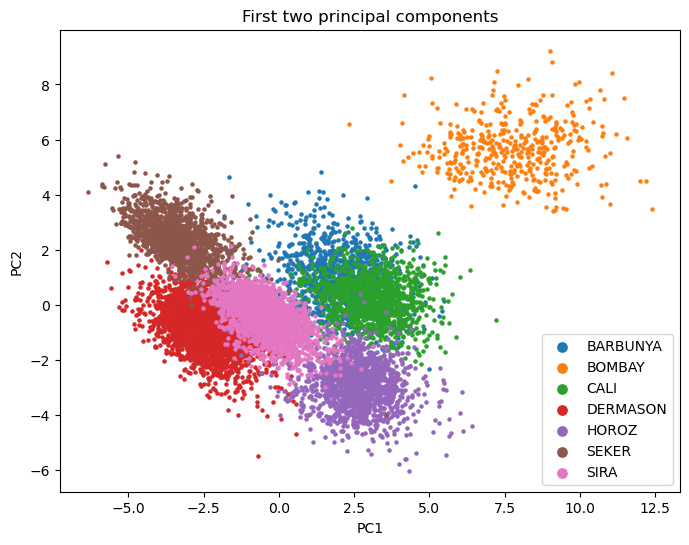

NameError: name 'best_name' is not defined

In [131]:
sc = StandardScaler().fit(x_train)
Xtr_s, Xte_s = sc.transform(x_train), sc.transform(x_test)

pca_full = PCA().fit(Xtr_s)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
k = int(np.argmax(cum >= 0.95)) + 1
print(f"Components needed for 95% variance: {k}")

plt.bar(range(1, len(evr) + 1), evr, label="Per component")
plt.plot(range(1, len(evr) + 1), cum, "r-o", label="Cumulative")
plt.axhline(0.95, color="gray", ls="--")
plt.xlabel("Component")
plt.ylabel("Explained variance ratio")
plt.legend()
plt.show()

pca = PCA(n_components=k).fit(Xtr_s)
Xtr_p, Xte_p = pca.transform(Xtr_s), pca.transform(Xte_s)

plt.figure(figsize=(8, 6))
for i, c in enumerate(classes):
    plt.scatter(Xtr_p[y_train == i, 0], Xtr_p[y_train == i, 1], s=5, label=c)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(markerscale=3)
plt.title("First two principal components")
plt.show()

res_pca = evaluate("PCA model", clone(models[best_name]), Xtr_p, Xte_p)

Top 6 features: ['Perimeter', 'ShapeFactor3', 'Compactness', 'ShapeFactor1', 'MinorAxisLength', 'ConvexArea']


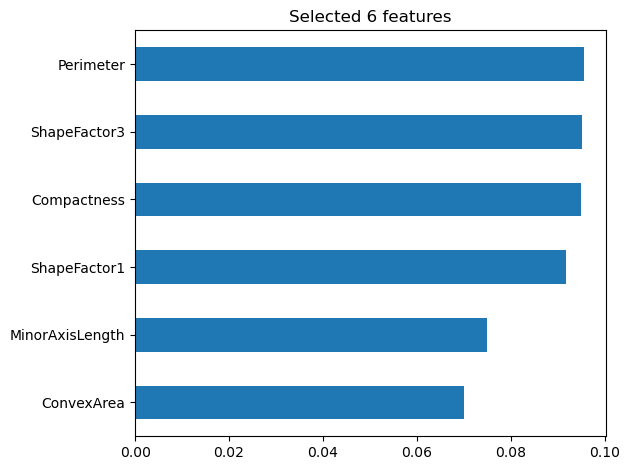

NameError: name 'best_name' is not defined

In [132]:
top6 = imp.index[:6]
print("Top 6 features:", list(top6))
imp[top6].sort_values().plot(kind="barh", title="Selected 6 features")
plt.tight_layout()
plt.show()

res_fs = evaluate("Feature-selected model", clone(models[best_name]),
                  x_train[top6], x_test[top6])

In [133]:
metrics = ["Precision", "Recall", "Accuracy", "F1"]
print("PCA-reduced model:")
print({m: round(res_pca[m], 4) for m in metrics})
print("Feature-selected model:")
print({m: round(res_fs[m], 4) for m in metrics})

final = pd.DataFrame({
    f"Original ({best_name}, 16 feat)": results[best_name],
    f"PCA ({k} comps)": res_pca,
    "Feature-selected (6 feat)": res_fs,
}).T[metrics + ["Time(s)"]]
print(final.round(4))

PCA-reduced model:


NameError: name 'res_pca' is not defined